# Step 5 – AOI maps

Maps of the scene footprints, in a projection chosen from the location of the data:
- Antarctica: WGS 84 / Antarctic Polar Stereographic (EPSG:3031)
- Arctic: WGS 84 / NSIDC Sea Ice Polar Stereographic North (EPSG:3413)
- elsewhere: WGS 84 / UTM zone of the scene

| Map | Content | File |
|---|---|---|
| overview | all selected scenes, one colour per stack, labelled with the area name | `<OUTPUT_DIR>/aoi_overview.png` |
| per stack | zoom on the stack, every acquisition by date | `<OUTPUT_DIR>/<stack folder>/<stack ID>_aoi.png` |
| per scene | zoom on one scene | `<OUTPUT_DIR>/<stack folder>/L1C/<product>/<product>_aoi.png` |

With `AREA_NAMES` (5.3) you can give each stack the name of its area, e.g. a glacier or ice shelf. The name is used as the title of the stack and scene maps and as the label on the overview map.

The basemap (land, ice shelves and shaded relief) comes from Natural Earth (public domain) and is downloaded once into the `natural_earth` folder.
**Output folders**: every run gets its own folder with a time stamp, so earlier results are never overwritten. Inside it, the folders mirror the input folders, so every result can be traced back to its product:
`<OUTPUT_DIR>/<date_time>_<analysis>[_<label>]/<stack folder>/L1C/<product>/<product>_<analysis>.png` (and `.tif`).
Each run folder has a `run_info.json` (settings and scenes of the run), and each stack folder a `stack_info.json` (stack ID, primary, what has been processed).

**How to use**
0. First time only: run **5.0** to install the packages, then restart the kernel.
1. Set `DATA_DIR` and `OUTPUT_DIR` in **5.1**, then run **5.1** and **5.2**: they load the tools and list all stacks (with their stack ID) and scenes.
2. Fill in **5.3 Settings**: which stacks and scenes to map, and the area names.
3. Run **5.4**.

`BiomassProduct.py` (ESA) and `polsar_utils.py` must be in the same folder as this notebook.

## 5.0 First time only: install the packages
Run once, then restart the kernel (**Kernel → Restart Kernel**). `--user` installs them in your home folder, so they are kept when the server restarts. Skip this cell if 5.1 runs without errors.

In [1]:
%pip install --user matplotlib numpy scipy rasterio netCDF4 xarray folium shapely pillow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 128.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 166.2 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.1/39.1 MB 127.7 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 122.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 78.3 MB/s  0:00:00
   ━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/9 [fonttools]  WARNING: The scripts fonttools, pyftmerge, pyftsubset and ttx are installed in '/home/jovyan/.local/bin' which is not on PATH.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━ 7/9 [rasterio]  WARNING: The script rio is installed in '/home/jovyan/.local/bin' which is not on PATH.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## 5.1 Load the tools and choose the folders
- `DATA_DIR`: the folder that contains your stacks. It can be a folder on your computer or a cloud bucket mounted as a folder. Leave it as `None` to search automatically.
- `OUTPUT_DIR`: the main folder for all results. It is created if it does not exist; `~` is your home folder.

In [3]:
ls


01_Find_Stream_BiomassL1C_stack.ipynb  BPS_inputs_download.py  Output/
03_pauli.ipynb                         Bach/                   Wilkens/
04_cloude_pottier.ipynb                BiomassProduct.py       Wilkens.txt
05_aoi_map.ipynb                       Final_Nivlisen/         __pycache__/
06_circular_basis.ipynb                Input_biomass/          natural_earth/
07_interferometry.ipynb                Nivlisen/               polsar_utils.py
08_penetration_depth.ipynb             Nivlisen.txt            untitled1.txt


In [4]:
%matplotlib inline
import polsar_utils as pu

DATA_DIR = "/home/jovyan/shared-buckets/6e08893c-463e-498b-92d2-6761dd17160d/biomass_inputs"  # e.g. "/path/to/biomass_inputs"; None = search automatically
OUTPUT_DIR = "/home/jovyan/idas_dump/test/George_VI"  # main folder for all result

## 5.2 Overview of the data

In [5]:
stacks = pu.find_stacks(DATA_DIR)
pu.print_overview(stacks)

8 stack(s), 55 scene(s)

[0] BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS  (6 scenes)
      [0] 2026-07-04 16:11             BIO_S1_STA__1S_20260704T161134_20260704T161157_T_G01_M04_C01_T010_F217_02_DV88YC
      [1] 2026-07-07 16:11             BIO_S1_STA__1S_20260707T161136_20260707T161159_T_G01_M04_C02_T010_F217_02_DV88Z2
      [2] 2026-07-10 16:11             BIO_S1_STA__1S_20260710T161138_20260710T161201_T_G01_M04_C03_T010_F217_02_DV88ZR
      [3] 2026-07-13 16:11  ★ primary  BIO_S1_STA__1S_20260713T161140_20260713T161203_T_G01_M04_C04_T010_F217_02_DV890B
      [4] 2026-07-19 16:11             BIO_S1_STA__1S_20260719T161143_20260719T161207_T_G01_M04_C06_T010_F217_02_DV890Y
      [5] 2026-07-22 16:11             BIO_S1_STA__1S_20260722T161145_20260722T161209_T_G01_M04_C07_T010_F217_02_DV891N
[1] BIO_S1_STA__ID_20260915T214352_20261003T214425_T_G01_M05_S0720_W0730_D_02_DZ1NQJ  (7 scenes)
      [0] 2026-09-15 21:43             BIO_S1_STA__1S_2026091

## 5.3 Settings
**Which data**
- `STACKS`: `"all"`, stack names such as `["stack_01", "stack_20"]`, stack IDs (the full ID or just its end, e.g. `["DZ1NQJ"]`), or numbers from the list in 5.2 such as `[0, 2]`
- `SCENES`: `"all"`, `"primary"` (only the primary of each stack), dates such as `["2026-09-15"]`, or numbers within each stack such as `[0, 3]`

Numbers start at 0, as in the list in 5.2.

**Area names**
- `AREA_NAMES`: the name of the area of each stack, shown in the map titles. Write the stack (its name, its stack ID or the end of the ID, as in the list in 5.2) and the name, e.g. `{"DZ1NQJ": "Pine Island Glacier", "stack_02": "Thwaites Glacier"}`. Stacks without a name keep the standard title. A single text such as `"Amundsen Sea Embayment"` is used for all maps and as the title of the overview map. `{}` = no names.

**Where the results go** (inside `OUTPUT_DIR` from 5.1)
- `NEW_RUN_FOLDER`: `True` = a new folder with a time stamp for every run (nothing is overwritten); `False` = write directly in `OUTPUT_DIR`
- `RUN_LABEL`: optional name added to the run folder, e.g. `"window200"`

**Maps**: set to `False` the maps you do not need.

In [6]:
STACKS = ["DTTNNX"]
SCENES = "all"

AREA_NAMES = {" George VI Ice Shelf"}  # e.g. {"DZ1NQJ": "Pine Island Glacier"}

NEW_RUN_FOLDER = True
RUN_LABEL = ""
OVERVIEW_MAP = True
STACK_MAPS = True
SCENE_MAPS = True
SHOW_FIGURES = True

## 5.4 Run

Selected 7 scene(s) in 1 stack(s):
   stack_27 | 2026-06-05 21:34 | BIO_S3_STA__1S_20260605T213439_20260605T213459_T_G01_M03_C01_T028_F217_02_DTTQVO
   stack_27 | 2026-06-08 21:34 | BIO_S3_STA__1S_20260608T213441_20260608T213502_T_G01_M03_C02_T028_F217_02_DTTQX3
   stack_27 | 2026-06-11 21:34 | BIO_S3_STA__1S_20260611T213443_20260611T213504_T_G01_M03_C03_T028_F217_02_DTTQYG
   stack_27 | 2026-06-14 21:34  ★ primary | BIO_S3_STA__1S_20260614T213445_20260614T213506_T_G01_M03_C04_T028_F217_02_DTTQZO
   stack_27 | 2026-06-17 21:34 | BIO_S3_STA__1S_20260617T213447_20260617T213507_T_G01_M03_C05_T028_F217_02_DTTR0Y
   stack_27 | 2026-06-20 21:34 | BIO_S3_STA__1S_20260620T213449_20260620T213509_T_G01_M03_C06_T028_F217_02_DTTR2F
   stack_27 | 2026-06-23 21:34 | BIO_S3_STA__1S_20260623T213451_20260623T213511_T_G01_M03_C07_T028_F217_02_DTTR3N
New run folder: /home/jovyan/idas_dump/test/George_VI/2026-10-16_070141_aoi

Overview map


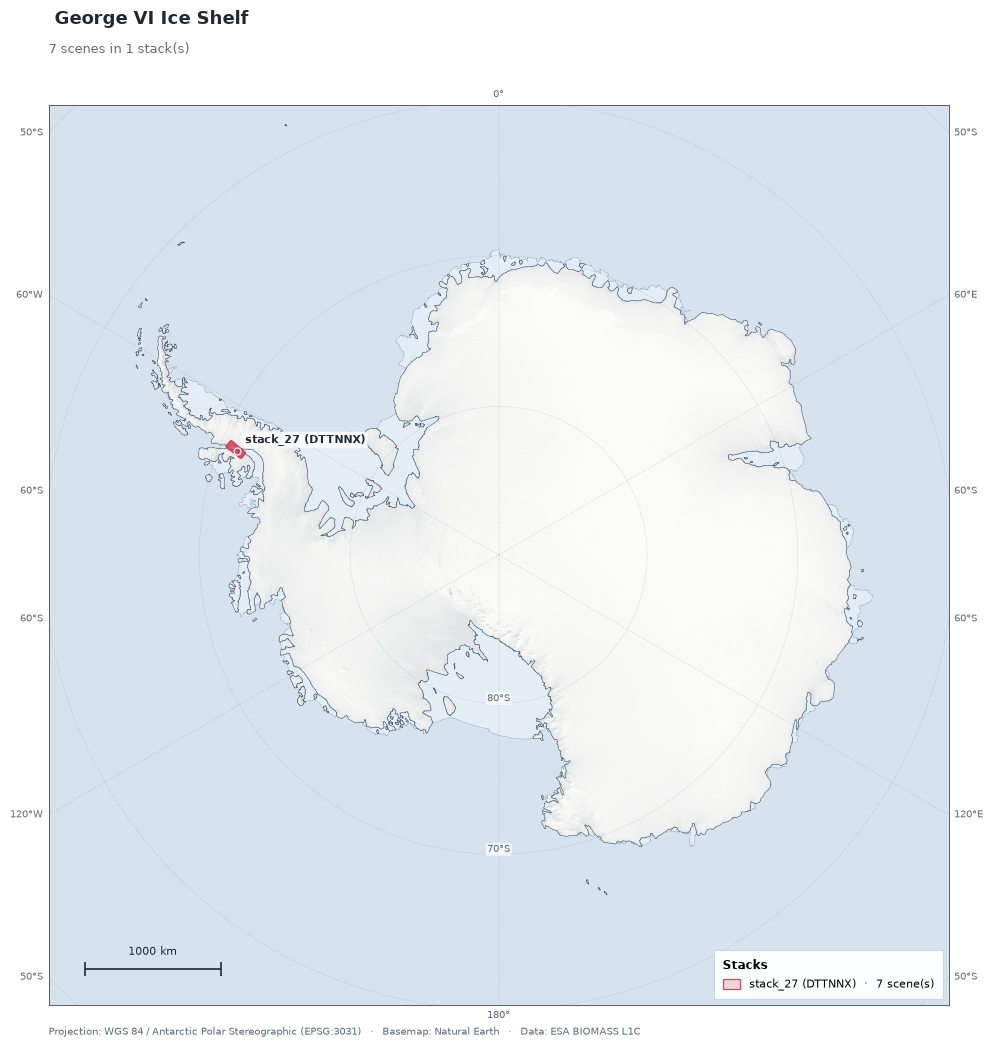

  saved aoi_overview.png

Stack map stack_27 (DTTNNX)


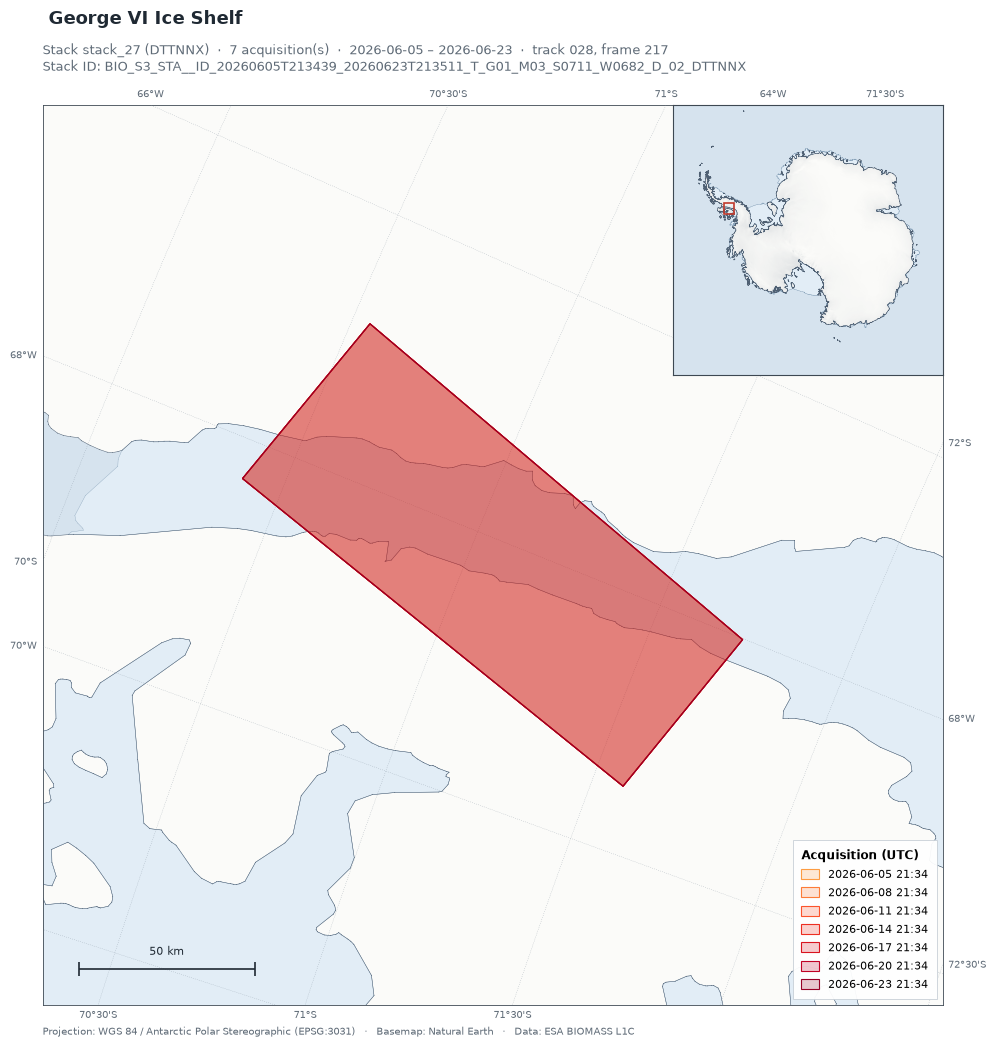

  saved BIO_S3_STA__ID_20260605T213439_20260623T213511_T_G01_M03_S0711_W0682_D_02_DTTNNX_aoi.png

Scene map stack_27 (DTTNNX)  2026-06-05 21:34


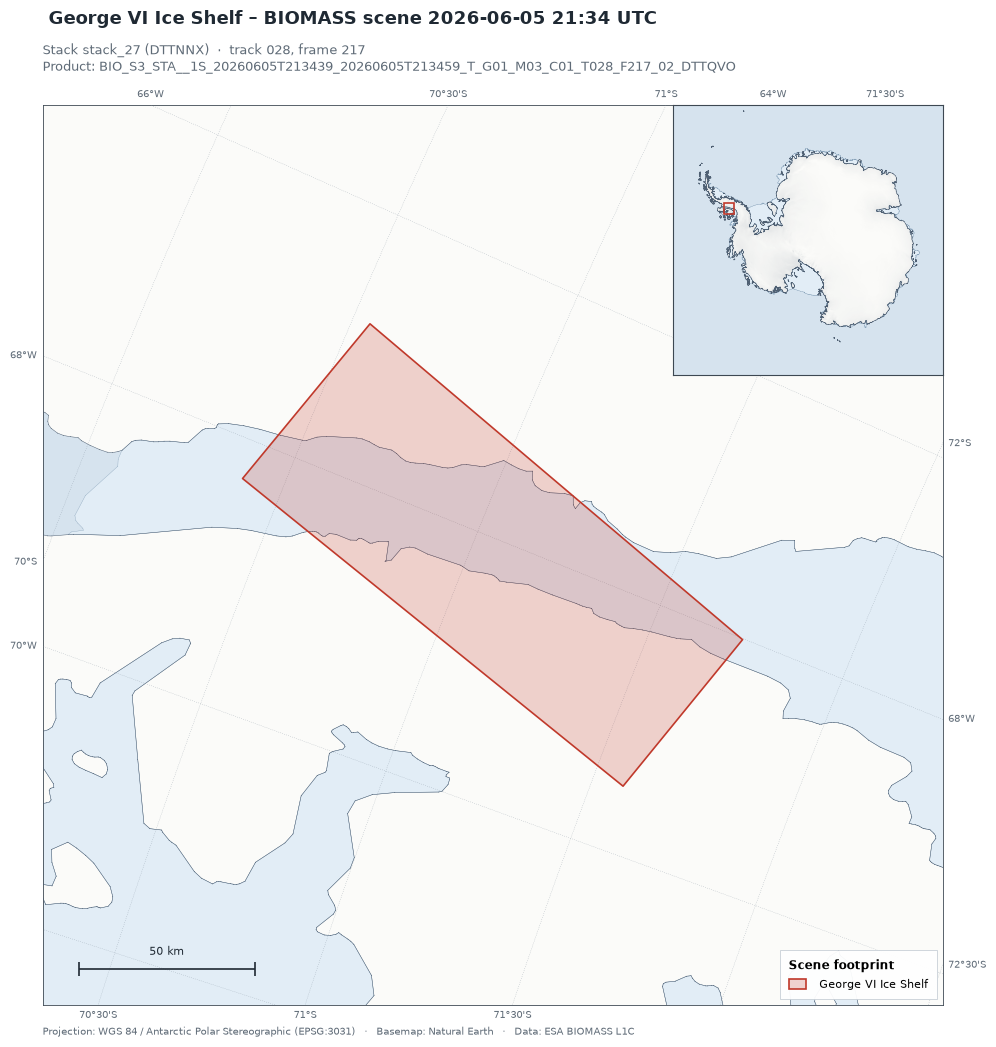

  saved BIO_S3_STA__1S_20260605T213439_20260605T213459_T_G01_M03_C01_T028_F217_02_DTTQVO_aoi.png

Scene map stack_27 (DTTNNX)  2026-06-08 21:34


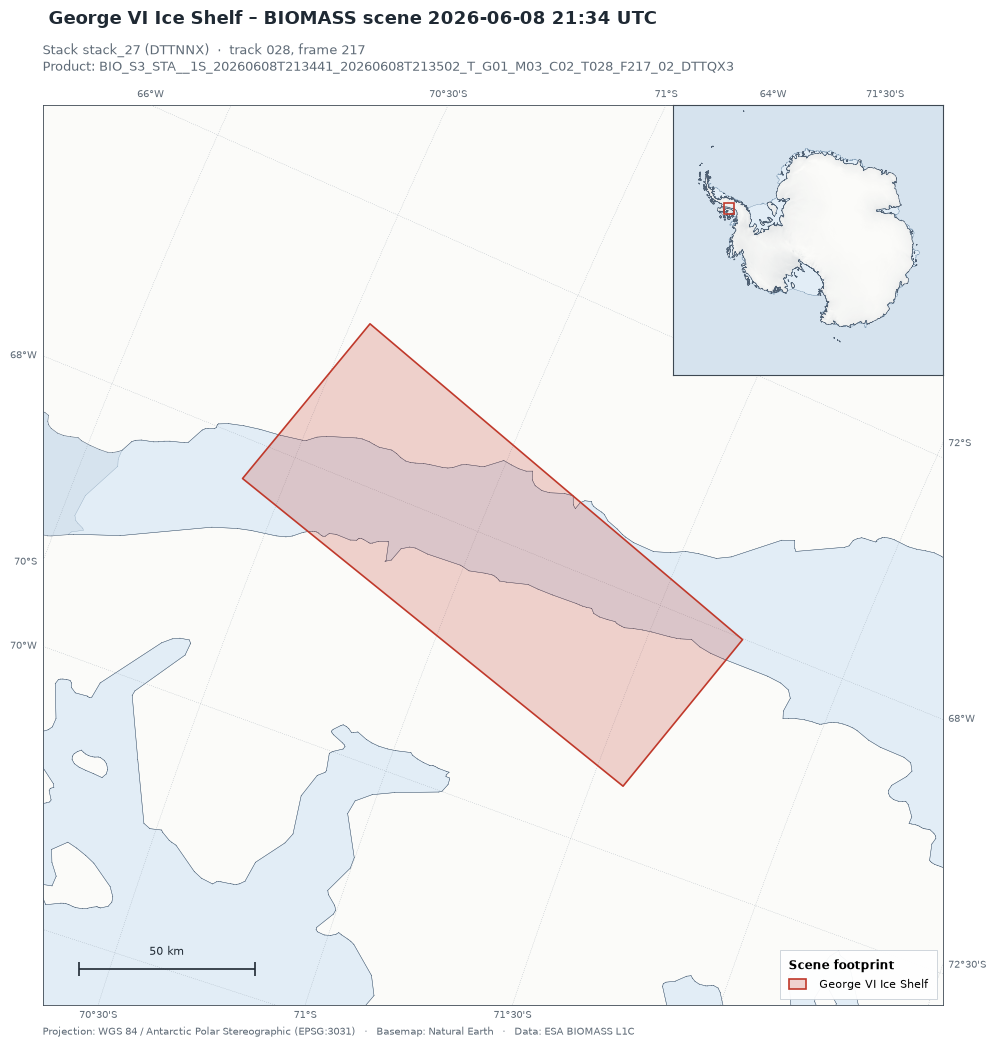

  saved BIO_S3_STA__1S_20260608T213441_20260608T213502_T_G01_M03_C02_T028_F217_02_DTTQX3_aoi.png

Scene map stack_27 (DTTNNX)  2026-06-11 21:34


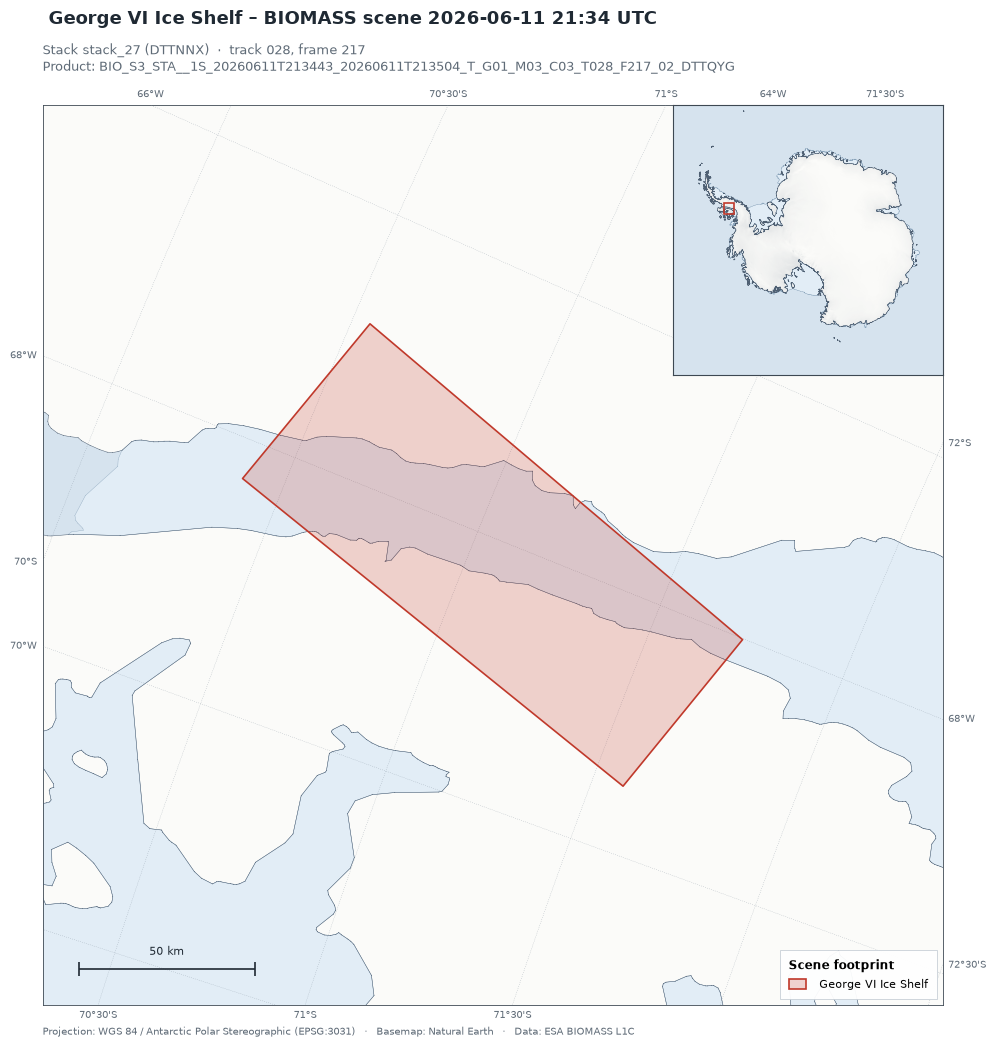

  saved BIO_S3_STA__1S_20260611T213443_20260611T213504_T_G01_M03_C03_T028_F217_02_DTTQYG_aoi.png

Scene map stack_27 (DTTNNX)  2026-06-14 21:34


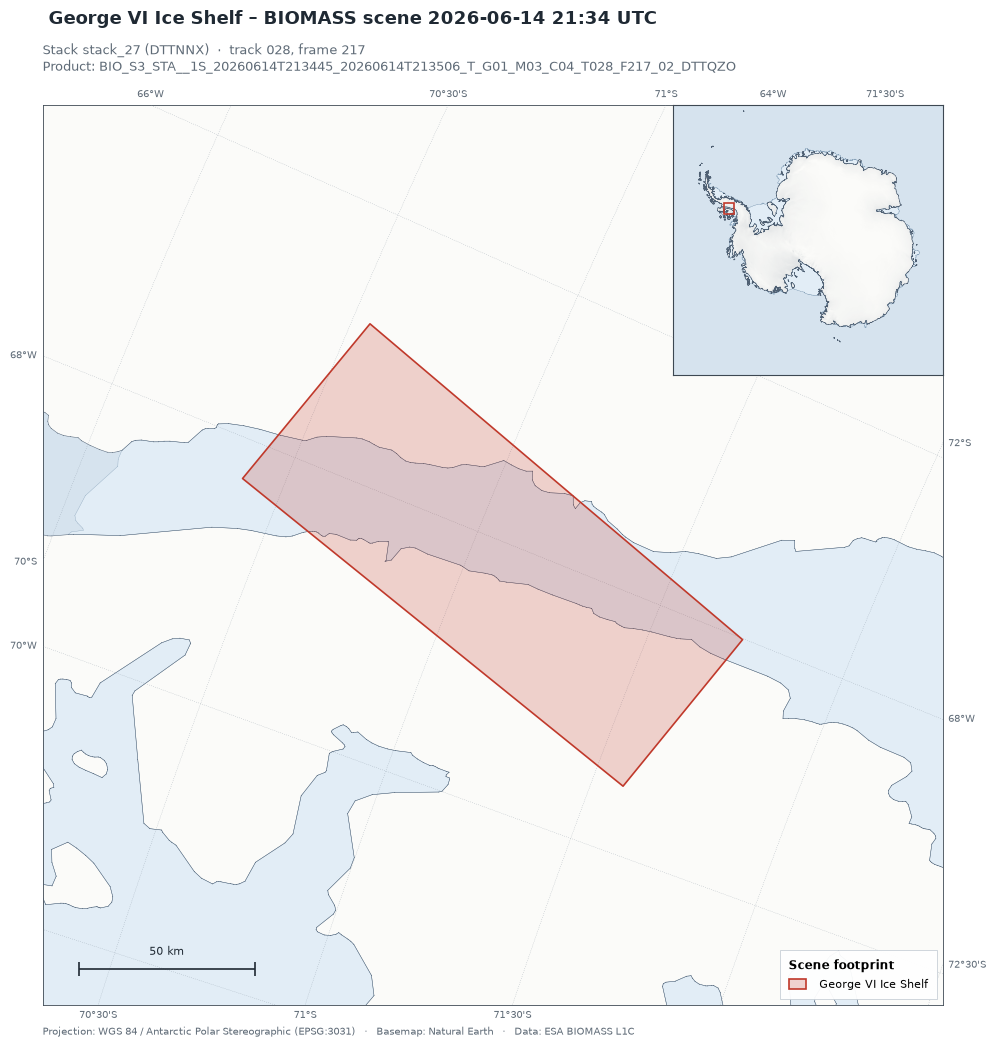

  saved BIO_S3_STA__1S_20260614T213445_20260614T213506_T_G01_M03_C04_T028_F217_02_DTTQZO_aoi.png

Scene map stack_27 (DTTNNX)  2026-06-17 21:34


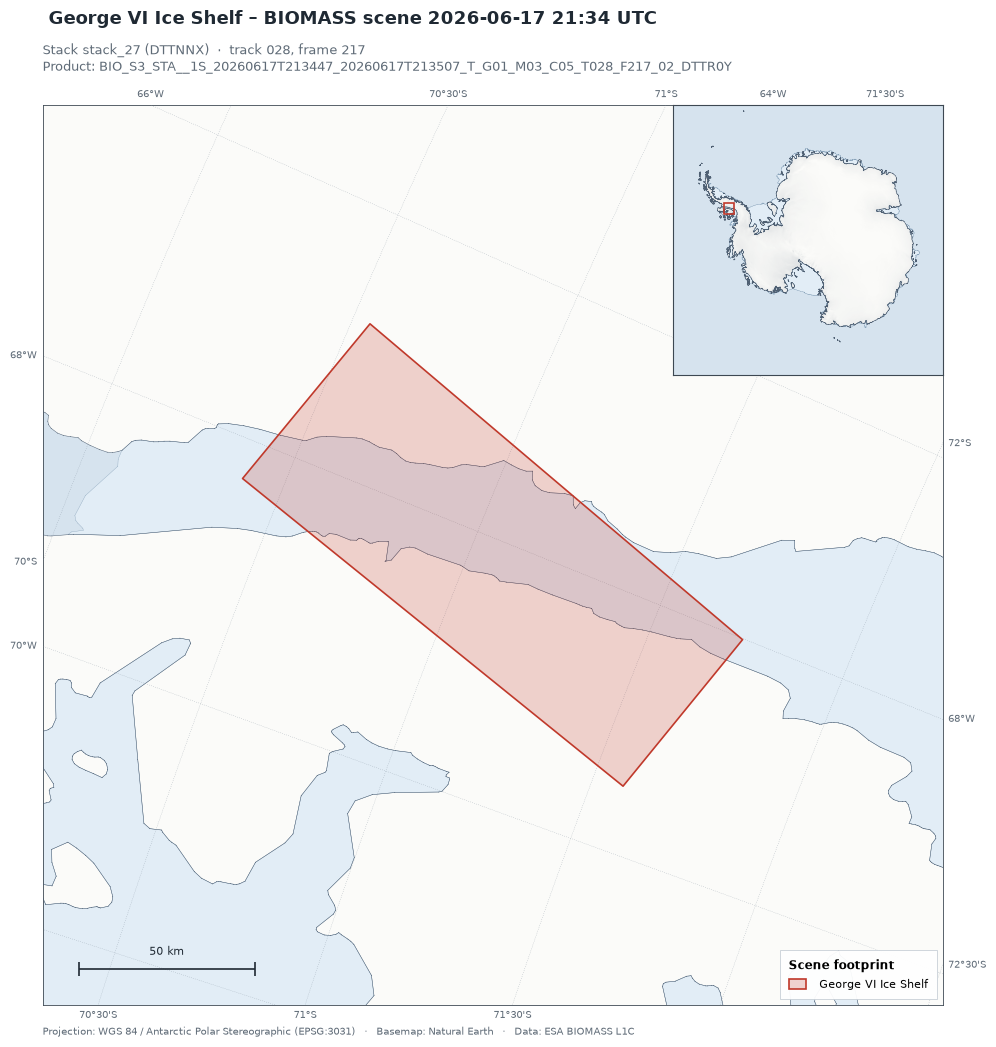

  saved BIO_S3_STA__1S_20260617T213447_20260617T213507_T_G01_M03_C05_T028_F217_02_DTTR0Y_aoi.png

Scene map stack_27 (DTTNNX)  2026-06-20 21:34


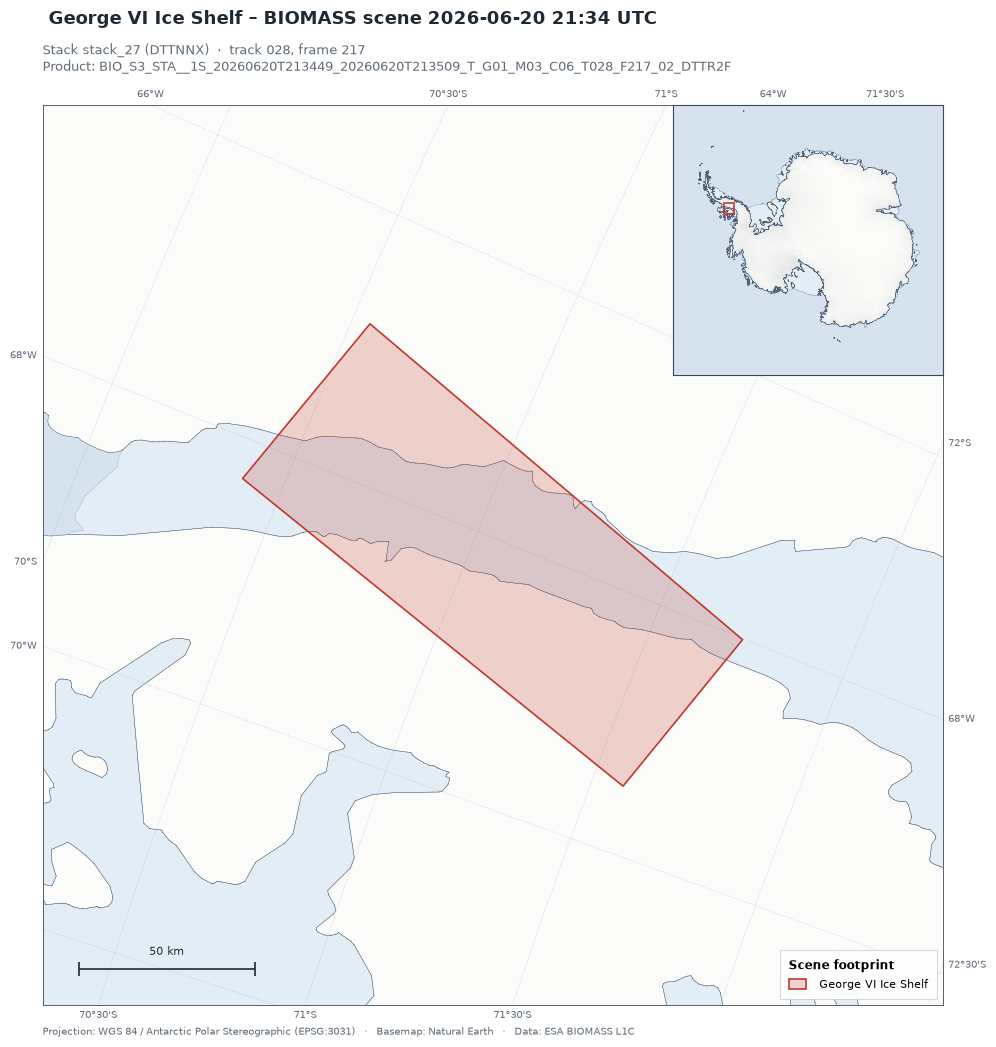

  saved BIO_S3_STA__1S_20260620T213449_20260620T213509_T_G01_M03_C06_T028_F217_02_DTTR2F_aoi.png

Scene map stack_27 (DTTNNX)  2026-06-23 21:34


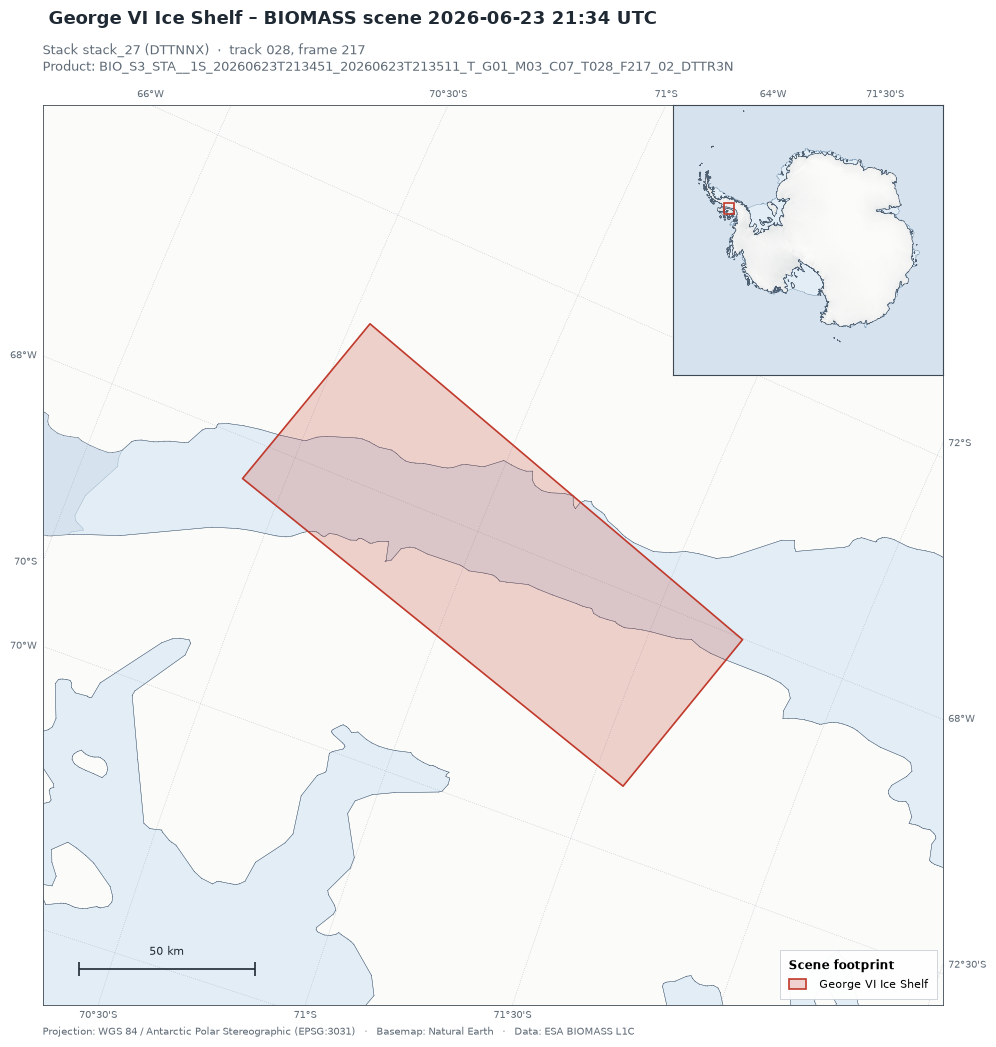

  saved BIO_S3_STA__1S_20260623T213451_20260623T213511_T_G01_M03_C07_T028_F217_02_DTTR3N_aoi.png


In [7]:
scenes = pu.select_scenes(stacks, STACKS, SCENES)
run_dir = pu.new_run_folder(OUTPUT_DIR, "aoi", NEW_RUN_FOLDER, RUN_LABEL,
                            settings=dict(overview=OVERVIEW_MAP, stack_maps=STACK_MAPS, scene_maps=SCENE_MAPS,
                                          area_names=AREA_NAMES, stacks=STACKS, scenes=SCENES), scenes=scenes)
pu.run_aoi_maps(scenes, run_dir, overview=OVERVIEW_MAP, per_stack=STACK_MAPS,
                per_scene=SCENE_MAPS, show=SHOW_FIGURES, area_names=AREA_NAMES)